<a href="https://colab.research.google.com/github/m4rtin1/text_summarization/blob/main/text_summarization_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loading the Dataset

In [1]:
from datasets import load_dataset

ds = load_dataset("abisee/cnn_dailymail", "3.0.0")

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  259MB            

... (4 outputs left out)

3.0.0/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

## Dataset to DataFrame Conversion

In [2]:
import pandas as pd

df_train = ds["train"].to_pandas()
df_val = ds["validation"].to_pandas()
df_test = ds["test"].to_pandas()

df = pd.concat([df_train, df_val, df_test], ignore_index=True)

## Dropping Unnecessary Columns

In [3]:
df_train.drop(columns=["id"], inplace=True)
df_val.drop(columns=["id"], inplace=True)
df_test.drop(columns=["id"], inplace=True)

df.drop(columns=["id"], inplace=True)

# Dataset Overview

## Inspecting The Data

In [4]:
print("Number of training examples:", df_train.shape[0])
print("Number of validation examples:", df_val.shape[0])
print("Number of testing examples:", df_test.shape[0])
print()
print("Total number of examples:", df.shape[0])

Number of training examples: 287113
Number of validation examples: 13368
Number of testing examples: 11490

Total number of examples: 311971


In [5]:
print("Number of duplicates in traning set:", df_train.duplicated().sum())
print("Number of duplicates in validation set:", df_val.duplicated().sum())
print("Number of duplicates in testing set:", df_test.duplicated().sum())
print()
print("Number of duplicates in entire dataset:", df.duplicated().sum())

Number of duplicates in traning set: 3098
Number of duplicates in validation set: 0
Number of duplicates in testing set: 2

Number of duplicates in entire dataset: 3101


In [6]:
df_train.drop_duplicates(inplace=True, keep="first")
df_test.drop_duplicates(inplace=True, keep="first")
df_val.drop_duplicates(inplace=True, keep="first")

df.drop_duplicates(inplace=True, keep="first")

In [7]:
print("Number of examples after removing duplicates")

print("Number of training examples:", df_train.shape[0])
print("Number of validation examples:", df_val.shape[0])
print("Number of testing examples:", df_test.shape[0])
print()
print("Total number of examples:", df.shape[0])

Number of examples after removing duplicates
Number of training examples: 284015
Number of validation examples: 13368
Number of testing examples: 11488

Total number of examples: 308870


## Article and Summary Analysis

In [13]:
# length = number of words including space
# chars = number of characters

df["article_length"] = df["article"].apply(lambda x: len(x.split()))
df["article_chars"] = df["article"].str.len()

df["highlights_length"] = df["highlights"].apply(lambda x: len(x.split()))
df["highlights_chars"] = df["highlights"].str.len()

In [29]:
print("Average article length:", round(df["article_length"].mean(), 3))
print("Average article characters:", round(df["article_chars"].mean(), 3))
print()
print("Average summary length:", round(df["highlights_length"].mean(), 3))
print("Average summary characters:", round(df["highlights_chars"].mean(), 3))
print()
print("Maximum article length:", df["article_length"].max())
print("Maximum article characters:", df["article_chars"].max())
print()
print("Maximum summary length:", df["highlights_length"].max())
print("Maximum summary characters:", df["highlights_chars"].max())
print()
print("Minimum article length:", df["article_length"].min())
print("Minimum article characters:", df["article_chars"].min())
print()
print("Minimum summary length:", df["highlights_length"].min())
print("Minimum summary characters:", df["highlights_chars"].min())

Average article length: 691.206
Average article characters: 4027.581

Average summary length: 52.045
Average summary characters: 297.156

Maximum article length: 2347
Maximum article characters: 15925

Maximum summary length: 1440
Maximum summary characters: 8541

Minimum article length: 8
Minimum article characters: 48

Minimum summary length: 4
Minimum summary characters: 14


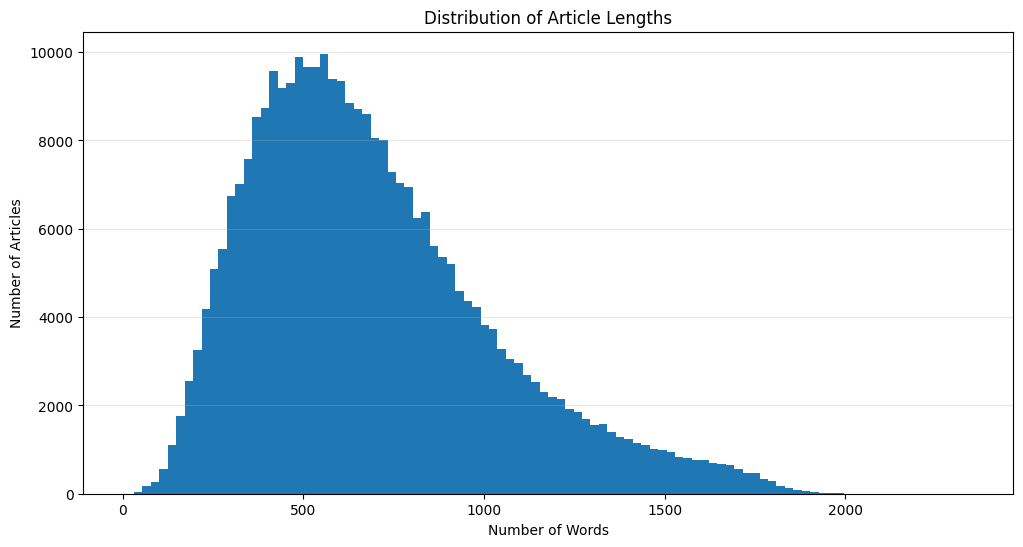

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.hist(df["article_length"], bins=100)
plt.title("Distribution of Article Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.grid(axis="y", alpha=0.3)

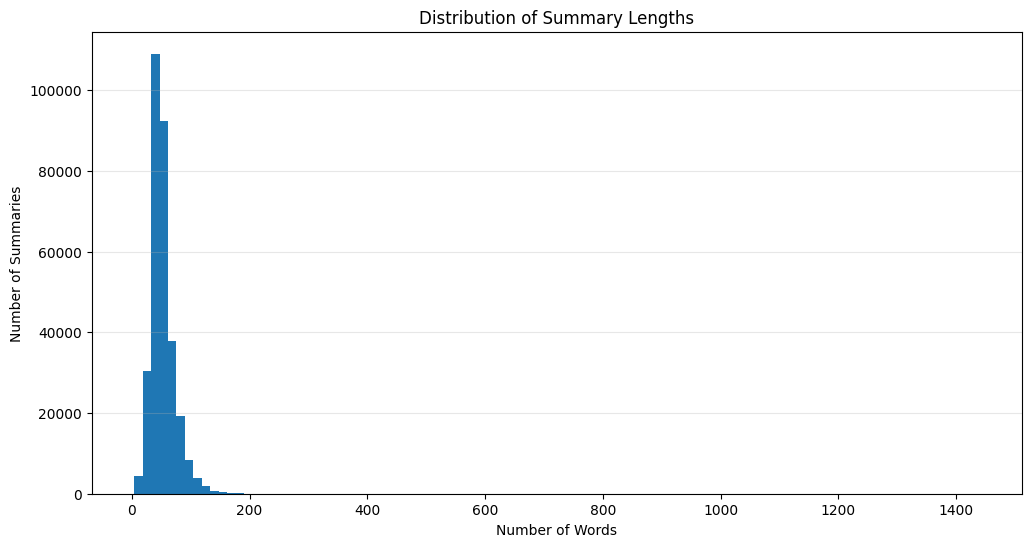

In [55]:
plt.figure(figsize=(12, 6))
plt.hist(df["highlights_length"], bins=100)
plt.title("Distribution of Summary Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Summaries")
plt.grid(axis="y", alpha=0.3)

In [63]:
# CR = Compression Ratio (summary / article)

df["CR_length"] = df["highlights_length"] / df["article_length"]
df["CR_chars"] = df["highlights_chars"] / df["article_chars"]

In [65]:
print("Average compression ratio words:", round(df["CR_length"].mean(), 3))
print("Maximum compression ratio words:", round(df["CR_length"].max(), 3))
print("Minimum compression ratio words:", round(df["CR_length"].min(), 3))
print()
print("Average compression ratio characters:", round(df["CR_chars"].mean(), 3))
print("Maximum compression ratio characters:", round(df["CR_chars"].max(), 3))
print("Minimum compression ratio characters:", round(df["CR_chars"].min(), 3))

Average compression ratio words: 0.092
Maximum compression ratio words: 19.0
Minimum compression ratio words: 0.005

Average compression ratio characters: 0.09
Maximum compression ratio characters: 18.333
Minimum compression ratio characters: 0.003


## Sentence-Level Analysis

In [61]:
import nltk
nltk.download("punkt_tab")
from nltk.tokenize import sent_tokenize

df["article_sentences"] = df["article"].apply(lambda x: len(sent_tokenize(x)))
df["highlights_sentences"] = df["highlights"].apply(lambda x: len(sent_tokenize(x)))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [66]:
# Compression Ration sentence level

df["CR_sentences"] = df["highlights_sentences"] / df["article_sentences"]

In [69]:
print("Average compression ratio sentence", round(df["CR_sentences"].mean(), 3))
print("Maximum compression ratio sentence", round(df["CR_sentences"].max(), 3))
print("Minimum compression ratio sentence", round(df["CR_sentences"].min(), 3))

Average compression ratio sentence 0.129
Maximum compression ratio sentence 18.0
Minimum compression ratio sentence 0.004


In [97]:
df[df["CR_length"] > 1].shape[0]

32